In [1]:
# ==========================================================
# Import Required Libraries
# ==========================================================

import pyarrow.parquet as pq
from glob import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ==========================================================
# home_team.csv, and away_team.csv
#
# Run this section only once.
# If these CSV files already exist, skip this section.
# ==========================================================

away_team_files=glob(f'tennis_data/2024*/*/*/raw_match_parquet/away_team_[0-9]*.parquet')
away_team = pd.concat([pd.read_parquet(f, columns=["match_id","player_id" ,"full_name", "height","country","gender","current_rank","plays"])
                    for f in away_team_files],ignore_index=True,)
away_team.to_csv('./csv_files/away_team.csv',index=False)

home_team_files=glob(f'tennis_data/2024*/*/*/raw_match_parquet/home_team_[0-9]*.parquet')
home_team=pd.concat([pd.read_parquet(f,columns=["match_id","player_id" ,"full_name", "height","country","gender","current_rank","plays"])
                    for f in home_team_files],ignore_index=True)
home_team.to_csv('./csv_files/home_team.csv',index=False)

In [3]:
# Load the prepared home and away team datasets

away_team=pd.read_csv('./csv_files/away_team.csv')
home_team=pd.read_csv('./csv_files/home_team.csv')

Question 1: How many tennis players are included in dataset?

In [4]:
# Determine the total unique players involved in matches using player_id

number_of_players=pd.concat([away_team['player_id'],home_team['player_id']]).dropna().nunique()
print(f'Number of players using player_id: {number_of_players}')

Number of players using player_id: 2644


In [5]:
# Calculate the number of unique players across home and away teams using full_name

number_of_players=pd.concat([away_team['full_name'],home_team['full_name']]).dropna().nunique()
print(f'The number of players is calculated using full_name: {number_of_players}')

The number of players is calculated using full_name: 2651


Question 2: what is the average height of the players?

In [6]:
# Calculate the average player height across all teams
height=pd.concat([away_team['height'],home_team['height']]).dropna()
mean_height=height.mean().round(2)
print(f'The Average height of the players is: {mean_height}')

The Average height of the players is: 1.82


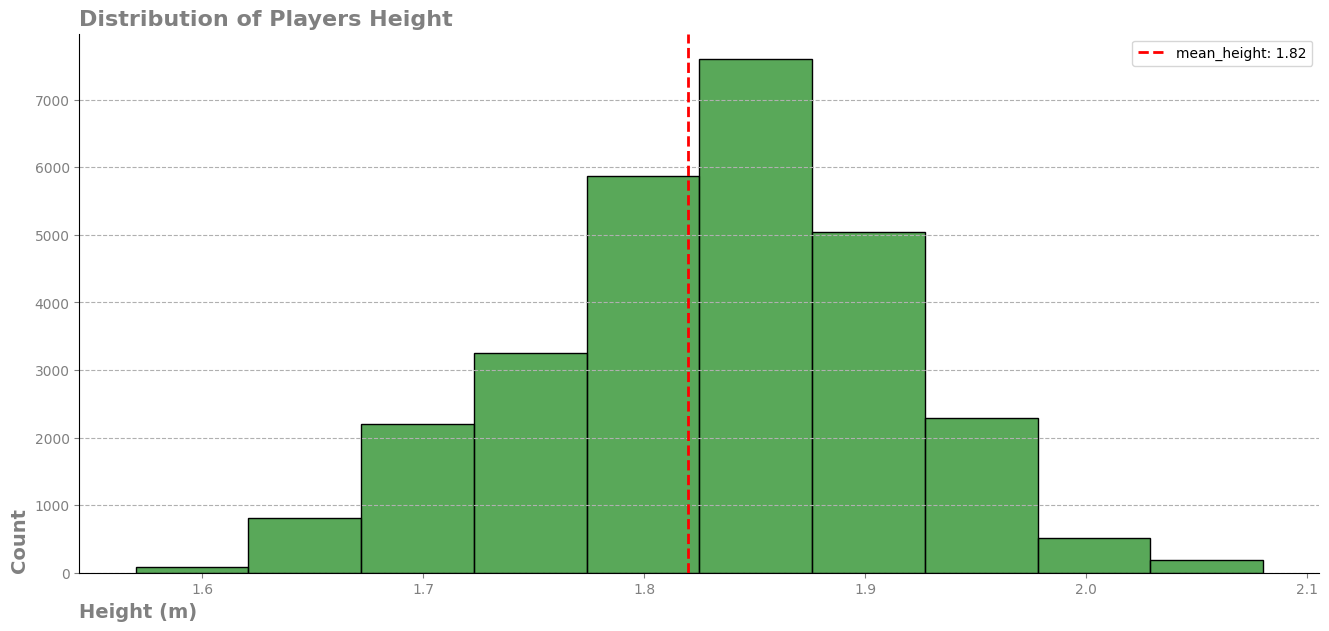

In [7]:
fig, ax = plt.subplots(figsize=(16,7))
sns.histplot(height, bins=10,color='#228B22', ax=ax)
ax.set_title("Distribution of Players Height",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Height (m)",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("Count",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
ax.grid(axis='y',linestyle='dashed')

ax.axvline(mean_height, color='red', linestyle='dashed', linewidth=2, 
            label=f'mean_height: {mean_height}')
ax.legend()
plt.show()


Question 3: Which player has the highest number of wins?

In [8]:
# ==========================================================
# Generate event.csv from raw parquet files
#
# Run this section only once.
# If event.csv already exists, skip this section.
#
# Added match_date column extracted from folder name.
# ==========================================================

files = glob('tennis_data/**/raw_match_parquet/event*.parquet', recursive=True)

all_data = []

for f in files:
    df = pd.read_parquet(f, columns=["match_id", "winner_code"])
    
    date_str = Path(f).parts[1] 
    df["match_date"] = pd.to_datetime(date_str, format="%Y%m%d")
    
    all_data.append(df)

event = pd.concat(all_data, ignore_index=True)
event.to_csv('./csv_files/event.csv', index=False)


In [9]:
# Load the preprocessed event dataset and convert match dates to datetime format

event=pd.read_csv('./csv_files/event.csv', parse_dates=['match_date'])

In [10]:
# Merge player information with match results
# to identify the winner of each match.

match_players=pd.merge(home_team[['match_id','full_name']],away_team[['match_id','full_name']],on='match_id',suffixes=['_home','_away'])
match=pd.merge(match_players,event,on='match_id').drop_duplicates()
match

,match_id,full_name_home,full_name_away,winner_code,match_date
0,11998445,"Cazaux, Arthur","Auger-Aliassime, Felix",2.0,2024-02-01
1,11998445,"Cazaux, Arthur","Auger-Aliassime, Felix",2.0,2024-02-02
4,11998446,"Lestienne, Constant",Flavio Cobolli,2.0,2024-02-01
5,11998446,"Lestienne, Constant",Flavio Cobolli,2.0,2024-02-02
8,11998447,"Ćorić, Borna","Martinez, Pedro",1.0,2024-02-01
...,...,...,...,...,...
99454,12212212,"Falabella, Lautaro Agustin","Derdoy, Felipe",1.0,2024-03-31
99455,12213156,"Damas, Miguel","Soriano Barrera, Adria",1.0,2024-03-31
99456,12213412,"Forejtek, Jonas","Taberner, Carlos",2.0,2024-03-31
99457,12213458,"Gorokhov, Mikhail","Simonsson, Fred",2.0,2024-03-31


In [11]:
# Identify the winner of each match and calculate
# the total wins for every player.

match['winner']=np.where(match['winner_code']==1 ,match['full_name_home'], match['full_name_away'])
winner=match['winner'].value_counts()
print(f"{winner.index[0]} has the most wins, with {winner.values[0]} victories.")
winner

Popko, Dmitry has the most wins, with 61 victories.


winner
Popko, Dmitry                        61
Chidekh, Clement                     56
Faria, Jaime                         46
Dellien Velasco, Murkel Alejandro    42
Clarke, Jay                          41
                                     ..
Lavino, Irene                         1
Carbonaro, Giulia                     1
Opitz, Jannik                         1
Reveniau, Simon                       1
Oluwadare, Hephzibah                  1
Name: count, Length: 2174, dtype: int64

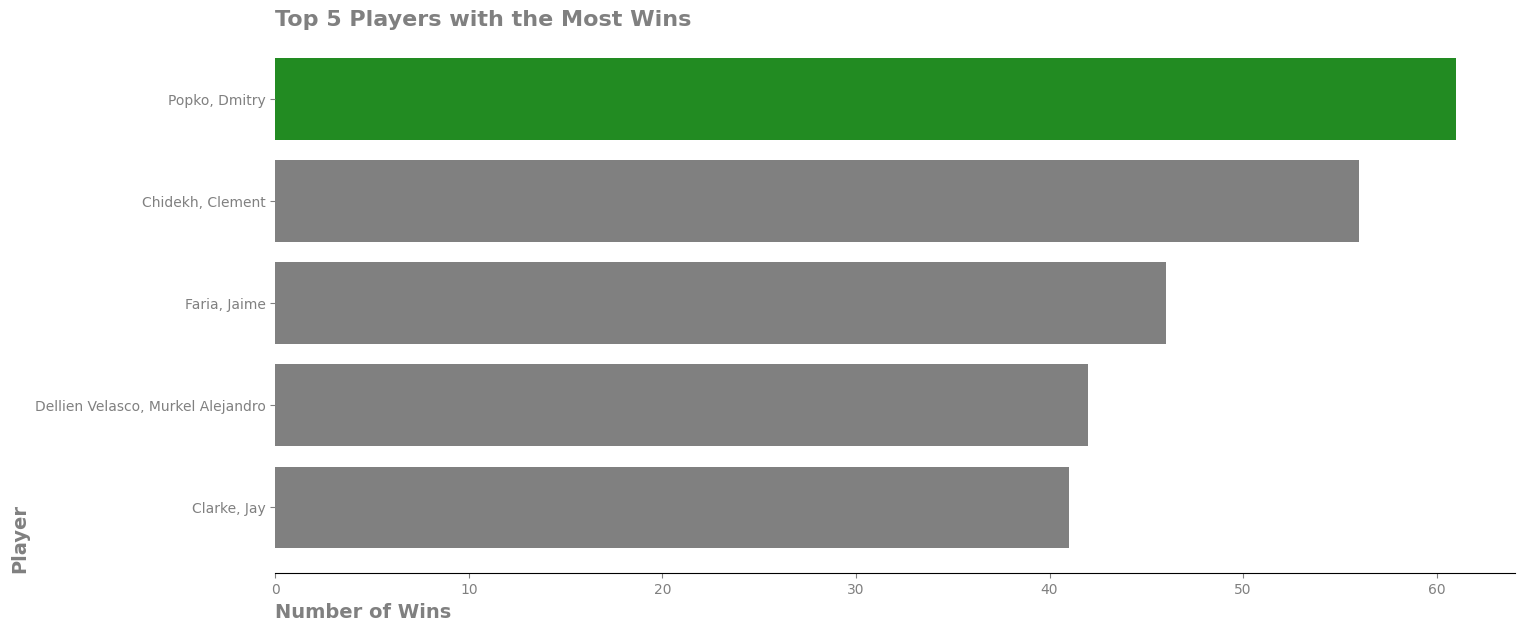

In [12]:
fig, ax = plt.subplots(figsize=(16,7))
ax.barh(winner.index[:5][::-1] , winner.values[:5][::-1],color=['gray','gray','gray','gray','#228B22'])
ax.set_title("Top 5 Players with the Most Wins",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Number of Wins",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("Player",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
plt.show()

Question 4:What is the longest match recorded in terms of duration?

In [13]:
# ==========================================================
# Create times.csv (Run Once)
# Used to calculate the total duration of each match.
# Skip this section if times.csv already exists.
# ==========================================================

times_files=glob('tennis_data/2024*/*/*/raw_match_parquet/time*.parquet')
times=pd.concat([pd.read_parquet(f,columns=['match_id','period_1','period_2','period_3','period_4','period_5'])
                for f in times_files],ignore_index=True)

times.to_csv('./csv_files/times.csv',index=False)

In [14]:
from datetime import timedelta

# Load the prepared match duration dataset
times=pd.read_csv('./csv_files/times.csv')

# Clean and prepare the duration columns
times[['period_1','period_2','period_3','period_4','period_5']] = times[['period_1','period_2','period_3','period_4','period_5']].apply(pd.to_numeric)
times=times.drop_duplicates().dropna(subset='period_1').fillna(0)

# Calculate the total duration of each match
times['total_time']=times[['period_1','period_2','period_3','period_4','period_5']].sum(axis=1)

# Remove unrealistic match durations using the IQR method
Q1 = times['total_time'].quantile(0.25)
Q3 = times['total_time'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

times = times[ (times['total_time'] >= lower_bound) & (times['total_time'] <= upper_bound) ]

# Find the longest valid match
longest_match = times.loc[times['total_time'].idxmax()]

match_id = longest_match['match_id']
duration = timedelta(seconds=int(longest_match['total_time']))

print(f"Match ID: {match_id}")
print(f"Duration: {duration}")

players = pd.concat([
    home_team.loc[home_team['match_id'] == match_id, 'full_name'],
    away_team.loc[away_team['match_id'] == match_id, 'full_name']
]).drop_duplicates()

print(f'players: {players.to_string(index=False)}')


Match ID: 12087277.0
Duration: 3:16:58
players: Pavlyuchenkova, Anastasia
           Kostyuk, Marta


Question 5: How many sets are typically played in a tennis match?

In [15]:
# Count the number of completed sets for each match
# by counting periods with a duration greater than zero.

times['number_of_sets']=(times[['period_1','period_2','period_3','period_4','period_5']]>0).sum(axis=1)

In [16]:
# Calculate the percentage distribution of matches
# based on the number of sets played.

set_counts=times['number_of_sets'].value_counts(normalize=True).mul(100).round(2)
set_counts

number_of_sets
2    69.38
3    29.90
1     0.72
Name: proportion, dtype: float64

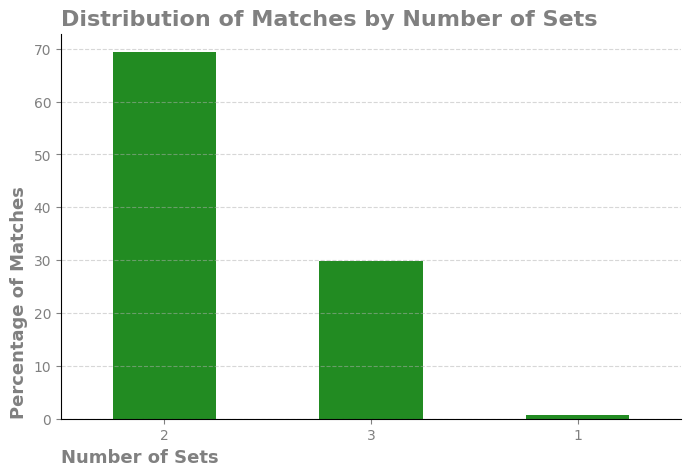

In [17]:
fig, ax = plt.subplots(figsize=(8,5))

set_counts.plot(kind='bar', ax=ax , color='#228B22')

ax.set_title('Distribution of Matches by Number of Sets',
    loc='left',fontsize=16, weight='bold', color='gray')

ax.set_xlabel('Number of Sets', loc='left', fontsize=13, weight='bold', color='gray')

ax.set_ylabel('Percentage of Matches', loc='bottom', fontsize=13, weight='bold', color='gray')

ax.spines[['top','right']].set_visible(False)
ax.tick_params(colors='gray' , rotation=0)
ax.grid(axis='y', linestyle='dashed', alpha=0.5)

plt.show()

Question 6 : Which country has produced the most successful tennis players?

In [18]:
country=pd.merge(home_team[['match_id','country']],away_team[['match_id','country']],on='match_id',suffixes=['_home','_away'])
match_countries=pd.merge(country,event[['match_id','winner_code']],on='match_id').drop_duplicates()
match_countries

,match_id,country_home,country_away,winner_code
0,11998445,France,Canada,2.0
4,11998446,France,Italy,2.0
8,11998447,Croatia,Spain,1.0
12,11998448,USA,France,1.0
13,11998449,France,France,2.0
...,...,...,...,...
99454,12212212,Argentina,Argentina,1.0
99455,12213156,Spain,Colombia,1.0
99456,12213412,Czech Republic,Spain,2.0
99457,12213458,Russia,Sweden,2.0


In [19]:
# Identify the winning country for each match and calculate the number of wins per country.

match_countries['winning_country']=(np.where(match_countries['winner_code']==1 
                                    ,match_countries['country_home'],match_countries['country_away']))
winning_country=match_countries['winning_country'].value_counts()
top_10_countries = winning_country.sort_values(ascending=False).head(10)
print("Top 10 countries by number of match wins:")
print(top_10_countries)

Top 10 countries by number of match wins:
winning_country
France            966
USA               842
Italy             779
Russia            589
Germany           500
Spain             463
Argentina         458
Japan             427
Australia         393
Czech Republic    348
Name: count, dtype: int64


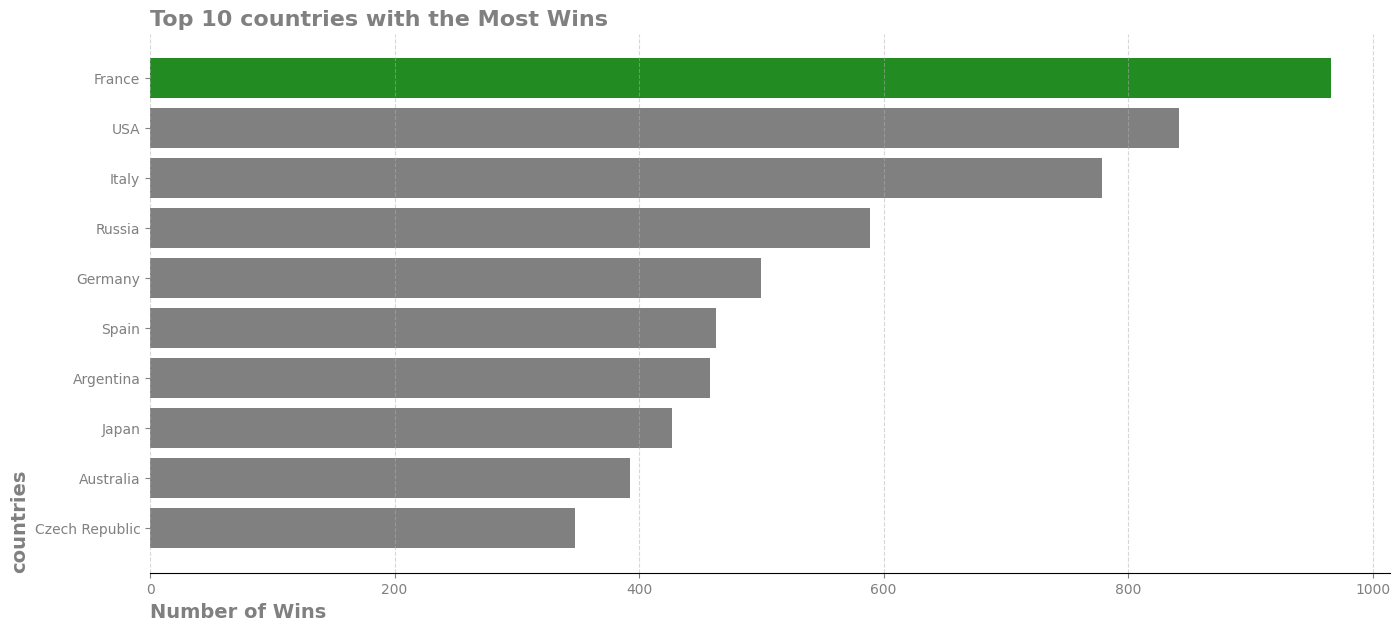

In [20]:
fig,ax=plt.subplots(figsize=(16,7))
ax.barh(top_10_countries.index[::-1],top_10_countries.values[::-1],
        color=['gray','gray','gray','gray','gray','gray','gray','gray','gray','#228B22'])
        
ax.set_title("Top 10 countries with the Most Wins",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Number of Wins",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("countries",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right','left']].set_visible(False)
ax.grid(axis='x',linestyle='dashed',alpha=0.5)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
plt.show()


Question 7 : What is the average number of aces per match?

In [21]:
# ==========================================================
# Create statistics.csv (Run Once)
# Merge all match statistics into a single CSV file.
# Skip if statistics.csv already exists.
# ==========================================================

statistics=glob('tennis_data/2024*/*/*/raw_statistics_parquet/*.parquet')
statistics=pd.concat([pd.read_parquet(f,columns=["match_id","period","statistic_name","home_value","away_value"])
                    for f in statistics],ignore_index=True)
statistics.to_csv('./csv_files/statistics.csv',index=False)

In [22]:
# Load the prepared statistic dataset

statistic=pd.read_csv('./csv_files/statistics.csv')

In [23]:
# Filter the overall ace statistics
#calculate the total aces per match, and compute the average number of aces across all matches.

statistic_ace = statistic[
    (statistic["statistic_name"] == "aces") &
    (statistic["period"] == "ALL")
].copy()

statistic_ace["home_value"] = pd.to_numeric(statistic_ace["home_value"], errors="coerce")
statistic_ace["away_value"] = pd.to_numeric(statistic_ace["away_value"], errors="coerce")

average_aces = (statistic_ace["home_value"] + statistic_ace["away_value"]).mean()

print(f"Average number of aces per match: {average_aces:.2f}")

Average number of aces per match: 5.35


Question 8: Is there a difference in the number of double faults based on gender?

In [24]:
# Merge match statistics with player gender
# compute total double faults per match, and compare the average by gender

player_gender=pd.concat([away_team,home_team])[['match_id','gender']]
double_faults_data=(pd.merge(statistic,player_gender,on='match_id')
                .drop_duplicates()
                .query('statistic_name == "double_faults" and period=="ALL"'))
double_faults_data['total_double_faults']=double_faults_data['home_value']+double_faults_data['away_value']

gender_faults=double_faults_data.groupby('gender')['total_double_faults'].mean().round(2)
gender_faults

gender
F    6.95
M    5.29
Name: total_double_faults, dtype: float64

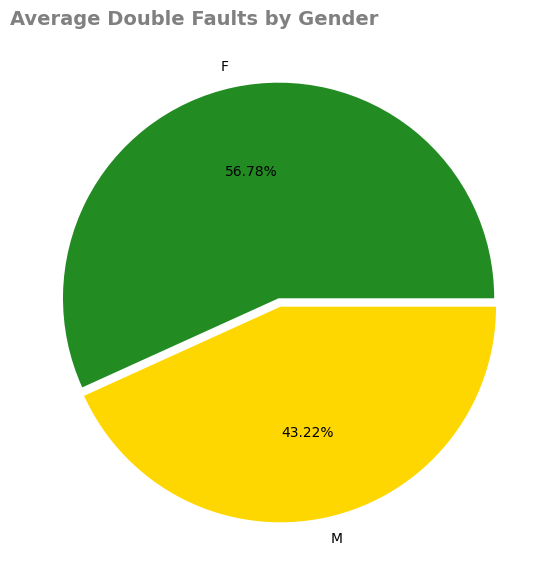

In [25]:
fig,ax=plt.subplots(figsize=(7,7))
plt.pie(gender_faults, labels=gender_faults.index, autopct='%1.2f%%', colors=['#228B22','#FFD700'],explode=(0.02, 0.02))
plt.title("Average Double Faults by Gender",loc='left',weight='bold',color='gray', fontsize=14)
plt.show()

Question 9 : Which player has won the most tournaments in a single month?

In [26]:
# ==========================================================
# This analysis uses the 'match' DataFrame created in Question 3,
# which merged home_team, away_team, and event data.
# We filtered for March matches to find the top performer.
# ==========================================================

match['winner']=np.where(match['winner_code']==1 ,match['full_name_home'], match['full_name_away'])
march_matches=match.query('match_date.dt.month == 3')
march_winner=march_matches['winner'].value_counts()
print(f"{march_winner.index[0]} has the most wins in March, with {march_winner.values[0]} victories.")
march_winner

Faria, Jaime has the most wins in March, with 34 victories.


winner
Faria, Jaime            34
Estable, Julieta        32
Popko, Dmitry           30
Nicod, Jakub            27
Squire, Henri           27
                        ..
Reveniau, Simon          1
Oluwadare, Hephzibah     1
Waldner, Niklas          1
Ratti, Lucio             1
Simonsson, Fred          1
Name: count, Length: 1694, dtype: int64

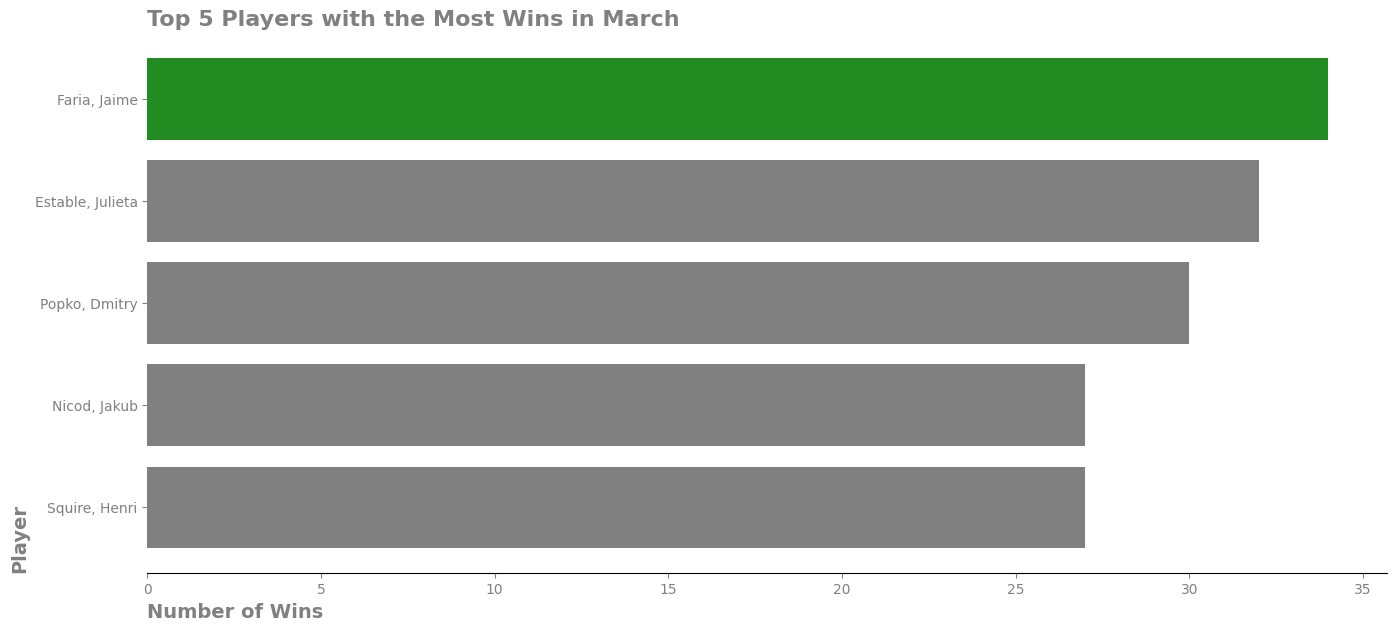

In [27]:
fig, ax = plt.subplots(figsize=(16,7))
ax.barh(march_winner.index[:5][::-1] , march_winner.values[:5][::-1],color=['gray','gray','gray','gray','#228B22'])
ax.set_title("Top 5 Players with the Most Wins in March",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Number of Wins",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("Player",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
plt.show()

In [28]:
# ==========================================================
# This analysis uses the 'match' DataFrame created in Question 3,
# which merged home_team, away_team, and event data.
# We filtered for March matches to find the top performer.
# ==========================================================

february_matches=match.query('match_date.dt.month == 2')
february_winner=february_matches['winner'].value_counts()
print(f"{february_winner.index[0]} has the most wins in february, with {february_winner.values[0]} victories.")
february_winner

Popko, Dmitry has the most wins in february, with 31 victories.


winner
Popko, Dmitry                   31
Chidekh, Clement                30
Hoang, Antoine                  27
Gengel, Marek                   27
Kužmová, Katarína               27
                                ..
Bidan, Fadi                      1
Konishi Camargo Silva, Julia     1
Zanolini, Camilla                1
Rioux, Lisa-Marie                1
Đaković , Mihaela                1
Name: count, Length: 1685, dtype: int64

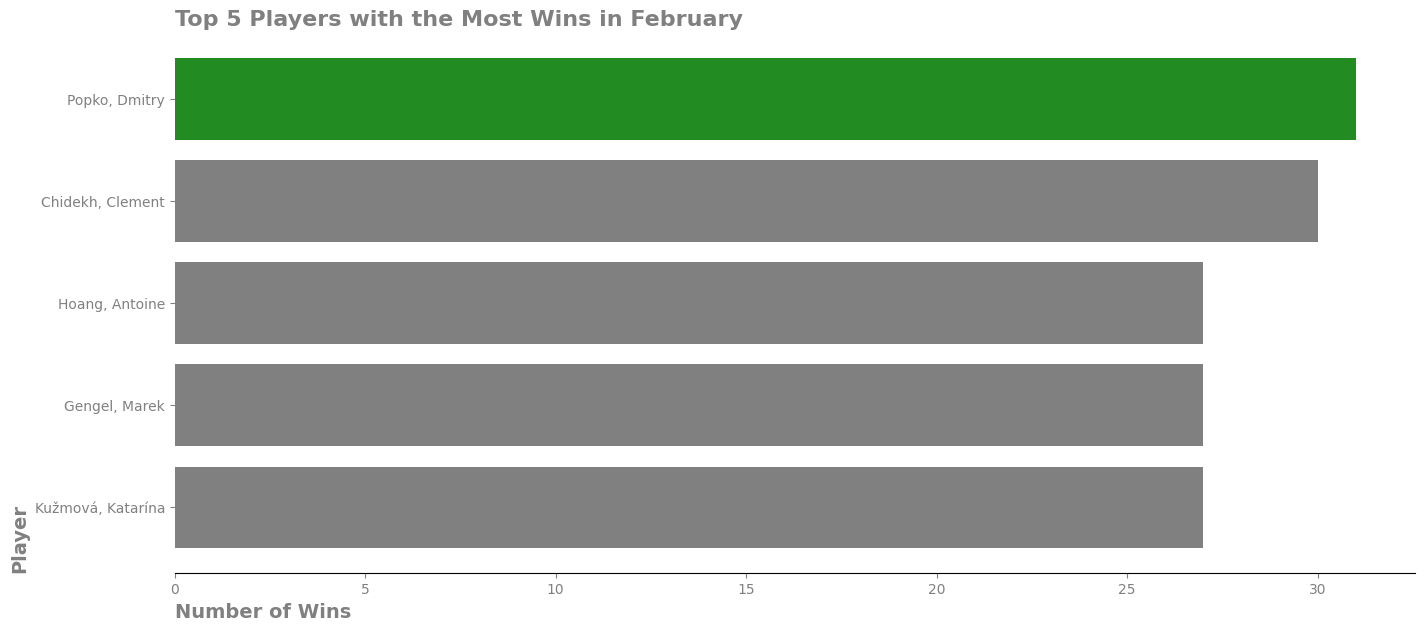

In [29]:
fig, ax = plt.subplots(figsize=(16,7))
ax.barh(february_winner.index[:5][::-1] , february_winner.values[:5][::-1],color=['gray','gray','gray','gray','#228B22'])
ax.set_title("Top 5 Players with the Most Wins in February",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Number of Wins",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("Player",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
plt.show()

Question 10: Is there a correlation between a player's height and their ranking?

In [30]:
# Keep one record per player, remove missing values, and calculate the correlation between player height and current ranking.
home_players_rank=home_team[["player_id", "height", "current_rank"]]
away_players_rank=away_team[["player_id", "height", "current_rank"]]
players_rank =pd.concat([home_players_rank,away_players_rank]).drop_duplicates(subset="player_id").dropna()
correlation = players_rank["height"].corr(players_rank["current_rank"])
print(f"Correlation: {correlation:.2f}")

Correlation: 0.11


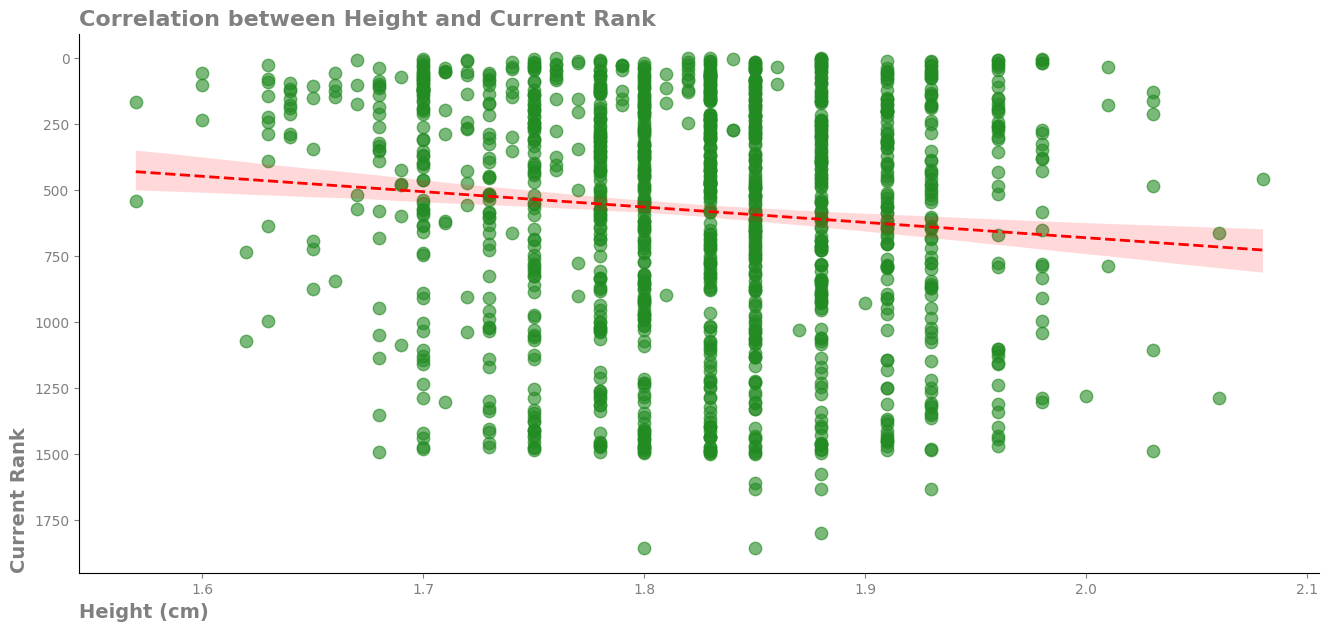

In [31]:
fig, ax = plt.subplots(figsize=(16,7))
sns.regplot( data=players_rank,x='height',y='current_rank',
    scatter_kws={'alpha':0.6, 's':80, 'color':'#228B22'},line_kws={'color':'red', 'linestyle':'--', 'linewidth':2},ax=ax)
ax.set_title("Correlation between Height and Current Rank",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Height (cm)",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel('Current Rank',loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
ax.invert_yaxis()
plt.show()

Question 11 : What is the average duration of matches?

In [32]:
# Reuse the match duration data from Question 4 and compute 
# the average duration of all recorded matches.
# The 'times' DataFrame contains total_time in seconds, 
# which we convert to a readable timedelta format.

average_duration = times["total_time"].mean()
duration = timedelta(seconds=int(average_duration))
print(f'Average duration: {duration}')

Average duration: 1:41:14


Question 12 : What is the average number of games per set in men's matches compared to women's matches?

In [33]:
# Merge point-by-point data from all matches and save it as a single CSV file.

pbp=glob('tennis_data/2024*/*/*/raw_point_by_point_parquet/*.parquet')
pbp=pd.concat([pd.read_parquet(f,columns=["match_id","set_id","game_id"])
                    for f in pbp],ignore_index=True)
pbp.to_csv('./csv_files/pbp.csv',index=False)

In [34]:
pbp=pd.read_csv('./csv_files/pbp.csv')

In [35]:
# Reuse the player_gender dataset from Question 8, count the number of games
# in each set, and compare the average between men's and women's matches.

match_gender = player_gender.drop_duplicates()

games_per_set = pbp.groupby(["match_id", "set_id"])["game_id"].nunique().reset_index(name="games_per_set")
games_with_gender = games_per_set.merge(match_gender,on="match_id")

average_games_per_set = games_with_gender.groupby("gender")["games_per_set"].mean().round(2)
print(average_games_per_set)

gender
F    8.90
M    9.27
Name: games_per_set, dtype: float64


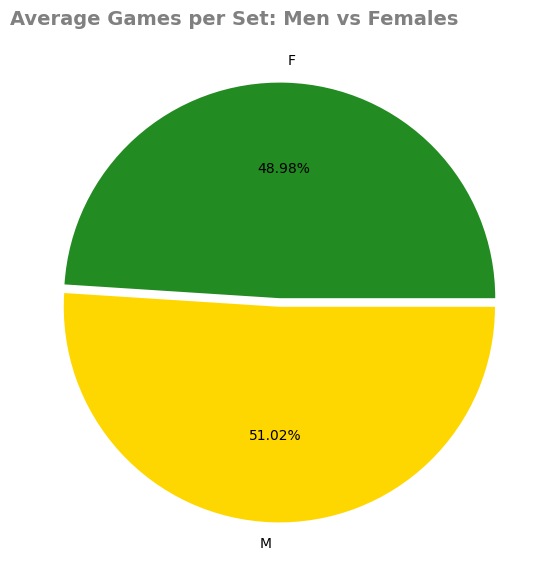

In [36]:
fig,ax=plt.subplots(figsize=(7,7))
plt.pie(average_games_per_set, labels=average_games_per_set.index, autopct='%1.2f%%', colors=['#228B22','#FFD700'],explode=(0.02, 0.02))
plt.title("Average Games per Set: Men vs Females",loc='left',weight='bold',color='gray', fontsize=14)
plt.show()

Question 13: What is the distribution of left-handed versus right-handed players?

In [37]:
# Replace missing playing style values with "Uncertain"
# and calculate the percentage distribution of left-handed and right-handed players.
home_plays=home_team[['player_id','plays']]
away_plays=away_team[['player_id','plays']]
plays=pd.concat([home_plays,away_plays]).drop_duplicates(subset='player_id')
players_hand=plays['plays'].fillna('Uncertain').value_counts(normalize=True).mul(100).round(2)
players_hand

plays
Uncertain       56.66
right-handed    38.31
left-handed      5.03
Name: proportion, dtype: float64

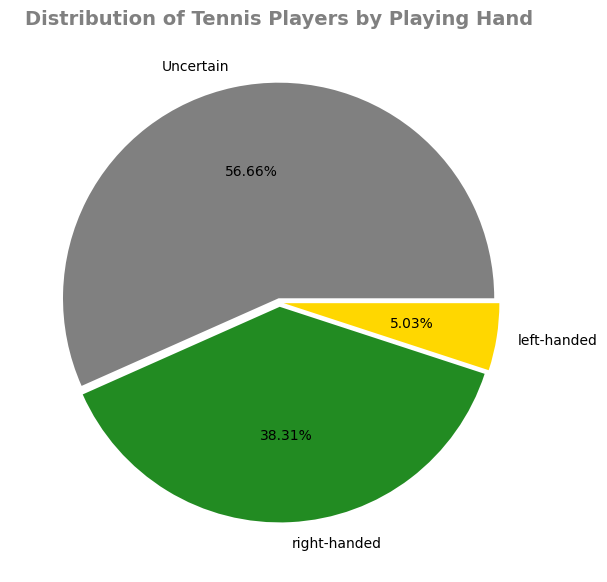

In [38]:
fig,ax=plt.subplots(figsize=(7,7))
plt.pie(players_hand,labels=players_hand.index, autopct='%1.2f%%', colors=['gray','#228B22','#FFD700'],explode=(0.02, 0.02,0.02))
plt.title('Distribution of Tennis Players by Playing Hand',weight='bold',color='gray', fontsize=14)
plt.show()

Question 14 : What is the most common type of surface used in tournaments?

In [39]:
# Merge tournament data from all matches and extract the ground type for each match.

ground_type_files=glob('tennis_data/*/*/*/raw_match_parquet/tournament*.parquet')
ground_type=pd.concat([pd.read_parquet(f,columns=['match_id','ground_type'])
                for f in ground_type_files],ignore_index=True)

ground_type.to_csv('./csv_files/ground_type.csv',index=False)

In [40]:
# Load the ground type dataset.

ground_type=pd.read_csv('./csv_files/ground_type.csv')

In [41]:
# Count the number of matches played on each ground type

matches_by_ground_type=ground_type['ground_type'].value_counts()
matches_by_ground_type

ground_type
Hardcourt outdoor    16959
Red clay             11856
Hardcourt indoor      4741
Red clay indoor        512
Grass                  509
Carpet indoor          276
Synthetic outdoor      226
Green clay              30
Name: count, dtype: int64

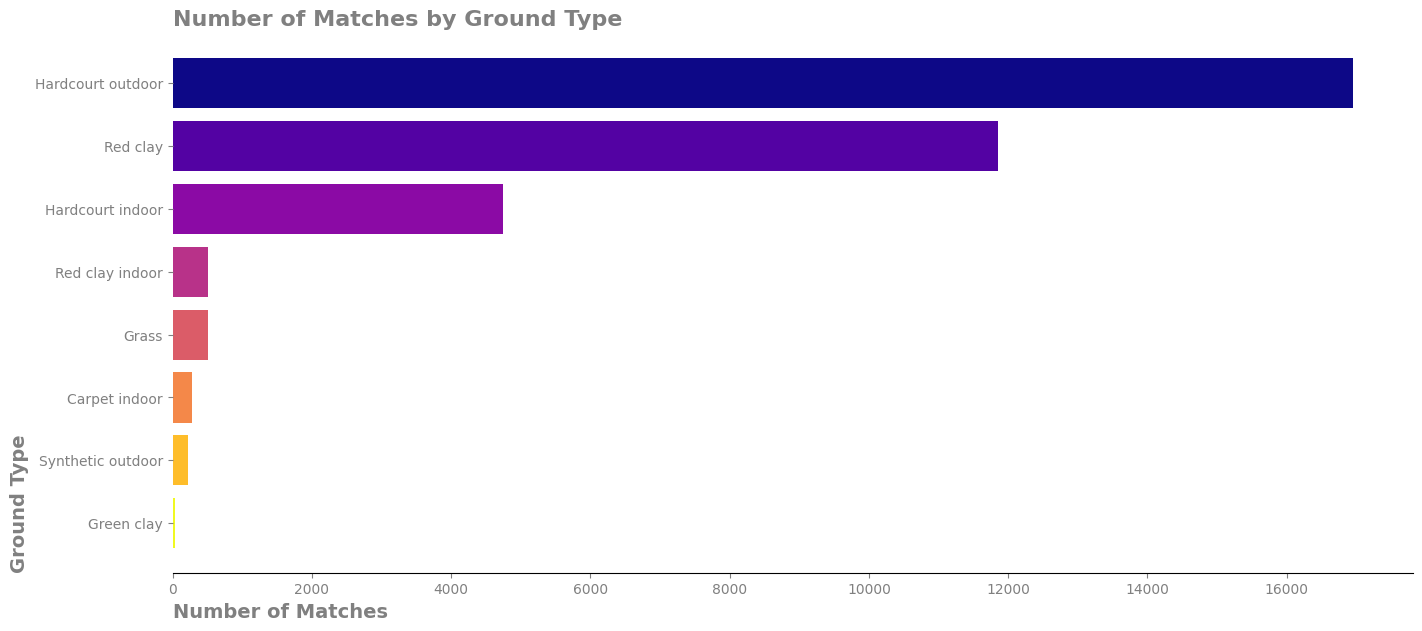

In [42]:
fig, ax = plt.subplots(figsize=(16,7))
colors = plt.colormaps['plasma'](np.linspace(0, 1, len(matches_by_ground_type)))
ax.barh(matches_by_ground_type.index[::-1] , matches_by_ground_type.values[::-1],color=colors[::-1])
ax.set_title("Number of Matches by Ground Type",loc='left',weight='bold',color='gray', fontsize=16)
ax.set_xlabel("Number of Matches",loc='left',weight='bold',color='gray',fontsize=14)
ax.set_ylabel("Ground Type",loc='bottom',weight='bold',color='gray',fontsize=14)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='x',colors='gray')
ax.tick_params(axis='y',colors='gray')
plt.show()

Question 15 : How many distinct countries are represented in the dataset?

In [43]:
# Merge venue data from all matches, extract unique venue countries, and save the result as a CSV file

venue_files=glob('tennis_data/2024*/*/*/raw_match_parquet/venue*.parquet')
venue_countries= pd.concat([pd.read_parquet(f, columns=["country"])
                    for f in venue_files],ignore_index=True).drop_duplicates()
venue_countries.to_csv('./csv_files/venue_countries.csv',index=False)

In [44]:
# Load the preprocessed venue countries dataset.

venue_countries=pd.read_csv('./csv_files/venue_countries.csv')

In [45]:
# Reuse country data from Question 6 and
# combine it with venue countries from the CSV file to count unique countries.

player_countries=country[['country_home','country_away']].unstack().drop_duplicates()
num_countries=pd.concat([venue_countries['country'],player_countries]).dropna().nunique()

print(f'There are {num_countries} distinct countries in the dataset')

There are 104 distinct countries in the dataset


Question 16 : Which player has the highest winning percentage against top 10 ranked opponents?

In [46]:
# Merge home and away players with rankings
matches = (home_team[['match_id', 'full_name', 'current_rank']]
    .merge(away_team[['match_id', 'full_name', 'current_rank']],
        on='match_id',suffixes=('_home', '_away')).drop_duplicates()
    .merge(event[['match_id', 'winner_code']], on='match_id'))

# Find the winner
matches['winner'] = np.where(
    matches['winner_code'] == 1,
    matches['full_name_home'],
    matches['full_name_away'])

# Create player perspective (home and away)
home = matches[['full_name_home', 'current_rank_away', 'full_name_away', 'winner']].copy()
home.columns = ['player', 'opponent_rank', 'opponent', 'winner']

away = matches[['full_name_away', 'current_rank_home', 'full_name_home', 'winner']].copy()
away.columns = ['player', 'opponent_rank', 'opponent', 'winner']

# Combine both perspectives
players = pd.concat([home, away], ignore_index=True)

# Keep only matches against top 10 ranked opponents
players = players[players['opponent_rank'] <= 10]

# Calculate win/loss
players['result'] = np.where(
    players['player'] == players['winner'],
    'Win',
    'Loss'
)

# Calculate winning percentage
answer = (
    players.groupby('player')
    .agg(
        matches_vs_top10=('result', 'count'),
        wins_vs_top10=('result', lambda x: (x == 'Win').sum())
    )
)

answer['win_percentage'] = (
    answer['wins_vs_top10'] /
    answer['matches_vs_top10'] * 100
).round(2)

# Final ranking
answer.sort_values(
    'win_percentage',
    ascending=False
)

,matches_vs_top10,wins_vs_top10,win_percentage
player,,,
"Altmaier, Daniel",8,8,100.0
"Avanesyan, Elina",2,2,100.0
"Thompson, Jordan",2,2,100.0
"Humbert, Ugo",12,12,100.0
"Kalinina, Anhelina",2,2,100.0
...,...,...,...
"Van De Zandschulp, Botic",2,0,0.0
"Zheng, Qinwen",2,0,0.0
"Zhang, Zhizhen",2,0,0.0


Question 17: What is the average number of breaks of serve per match?

In [47]:
# Load and combine break_occurred data from all tennis power files.

break_occurred_files=glob('tennis_data/2024*/*/*/raw_tennis_power*/*.parquet')
break_occurred= pd.concat([pd.read_parquet(f, columns=["match_id","set_num","value","break_occurred"])
                    for f in break_occurred_files],ignore_index=True).drop_duplicates()
break_occurred.to_csv('./csv_files/break_occurred.csv',index=False)

In [48]:
# Load the CSV file containing break-of-serve information for each match.

break_data=pd.read_csv('./csv_files/break_occurred.csv')

In [49]:
# Calculate the average number of service breaks per match by counting
# the breaks in each match and then taking the overall average

avg_breaks_of_serve=break_data.groupby('match_id')['break_occurred'].sum().mean().round(2)
print(f'The average number of breaks of serve per match is {avg_breaks_of_serve}')

The average number of breaks of serve per match is 7.5
